In [1]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import torch
from time import time
from utils import generate_position

In [2]:
DEFAULT_DATA = '/home/hep/lprate/projects/MuonsAndMatter/data/muons/full_sample_w.h5'
device = 'cuda:0'

In [3]:
def batch_sample(flow, n_samples, batch_size:int=1e6):
    samples = []
    batch_size = min(batch_size, n_samples)
    for i in range(int(n_samples/batch_size)):
        samples.append(flow.sample(batch_size).cpu().numpy())
    if n_samples % batch_size > 0:
        remainder = n_samples % batch_size
        samples.append(flow.sample(remainder).cpu().numpy())
    return np.concatenate(samples, axis=0)

In [4]:
data = {}
with h5py.File(DEFAULT_DATA, 'r') as f:
    for group_name in f.keys():
        print(f"Group: {group_name}")
        group = f[group_name]
        weight = group.attrs['weight']
        if float(weight) < 0.0001: continue
        px = group['px'][:]
        py = group['py'][:]
        pz = group['pz'][:]
        x_ = group['x'][:]
        y_ = group['y'][:]
        z_ = group['z'][:]
        pdg = group['pdg'][:]
        data[weight] = np.stack([px, py, pz, x_, y_, z_, pdg], axis=1)
        print(f"Weight: {weight}, Shape: {data[weight].shape}")

del px, py, pz, x_, y_, z_, pdg
pz_real = np.concatenate([data[weight][:, 2] for weight in data.keys()])
pt_real = np.sqrt(np.concatenate([data[weight][:, 0]**2 + data[weight][:, 1]**2 for weight in data.keys()]))
weights = np.concatenate([np.full(data[w].shape[0], float(w), dtype=float) for w in data.keys()])


Group: 0
Group: 1
Weight: 0.09369999915361404, Shape: (3311, 7)
Group: 2
Weight: 1.0, Shape: (20993, 7)
Group: 3
Weight: 3.2616000175476074, Shape: (691113, 7)
Group: 4
Weight: 7.6875, Shape: (480474935, 7)
Group: 5
Weight: 9.369999885559082, Shape: (168445, 7)
Group: 6
Weight: 326.1600036621094, Shape: (11094133, 7)
Group: 7
Weight: 768.75, Shape: (13921031, 7)


In [5]:
from models import NeuralSplineFlow
models = torch.load('outputs/flow_model.pt', map_location='cpu', weights_only=False)["groups"]

In [6]:
for w, e in models.items():
    flow = NeuralSplineFlow.from_config(e["config"])
    flow.load_state_dict(e["state_dict"])
    e["flow"] = flow.to('cpu').eval()

In [7]:
n_samples = 300e6
alpha = n_samples / sum([model['weight'] for model in models.values()])
gen_pz = []
gen_pt = []
for weight, model in models.items():
    real_weight = round(model['weight'] * alpha)
    if real_weight<1: continue
    flow = model['flow'].to(device)
    flow.eval()
    mean,std = model['mean'], model['std']
    t1 = time()
    print(f"Weight: {weight}")
    print("real_weight", real_weight)
    sample = batch_sample(flow, real_weight)
    sample = sample * std + mean
    print(f"Sampling {real_weight} samples took {time()-t1:.2f} seconds")
    gen_pz.append(sample[:, 0])
    gen_pt.append(sample[:, 1])

del sample, mean, std
gen_pz = np.concatenate(gen_pz)
gen_pt = np.concatenate(gen_pt)
print(f"Generated pz shape: {gen_pz.shape}, pt shape: {gen_pt.shape}")

Weight: 0.09369999915361404
real_weight 5
Sampling 5 samples took 0.34 seconds
Weight: 1.0
real_weight 350
Sampling 350 samples took 0.02 seconds
Weight: 3.2616000175476074
real_weight 37532
Sampling 37532 samples took 0.01 seconds
Weight: 7.6875
real_weight 61500171
Sampling 61500171 samples took 9.66 seconds
Weight: 9.369999885559082
real_weight 26280
Sampling 26280 samples took 0.01 seconds
Weight: 326.1600036621094
real_weight 60248263
Sampling 60248263 samples took 9.43 seconds
Weight: 768.75
real_weight 178187399
Sampling 178187399 samples took 28.14 seconds
Generated pz shape: (300000000,), pt shape: (300000000,)


In [8]:
from matplotlib.colors import LogNorm

def compare_1d_histograms(real_sample, gen_sample, bins=120, range_vals=None, xlabel="Value", real_w=None):
    """Overlays 1D distributions of real and generated samples."""
    fig, ax = plt.subplots(figsize=(8, 5))
    
    # Auto-detect range if none is provided
    if range_vals is None:
        range_vals = (min(np.min(real_sample), np.min(gen_sample)), 
                      max(np.max(real_sample), np.max(gen_sample)))
        
    b = np.linspace(range_vals[0], range_vals[1], bins)
    
    # Plot marginals
    ax.hist(real_sample, bins=b, weights=real_w, density=True, 
            histtype='step', color='k', label='Real')
    ax.hist(gen_sample, bins=b, density=True, 
            histtype='step', color='C1', label='Generated')
    
    ax.set_xlabel(xlabel, fontsize=14)
    ax.set_ylabel('Density', fontsize=14)
    ax.legend(fontsize=11)
    
    fig.tight_layout()
    return fig, ax


def compare_2d_histograms(real_pz, real_pt, gen_pz, gen_pt, real_w=None):
    """Creates side-by-side 2D Pz-Pt density histograms with a shared color scale."""
    pz_bins = np.linspace(0, 400, 201)
    pt_bins = np.linspace(0, 13, 201)
    
    # Calculate 2D densities
    Hr, _, _ = np.histogram2d(real_pz, real_pt, bins=[pz_bins, pt_bins], 
                              weights=real_w, density=True)
    Hg, _, _ = np.histogram2d(gen_pz, gen_pt, bins=[pz_bins, pt_bins], 
                              density=True)
    
    # Shared LogNorm for accurate visual comparison
    pos_vals = np.concatenate([Hr[Hr > 0].ravel(), Hg[Hg > 0].ravel()])
    norm = LogNorm(vmin=pos_vals.min(), vmax=max(Hr.max(), Hg.max()))
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
    
    # Draw meshes
    for ax, H, title in zip(axes, [Hr, Hg], ['Real', 'Generated']):
        im = ax.pcolormesh(pz_bins, pt_bins, H.T, cmap='viridis', norm=norm)
        ax.set_xlim(0, 400)
        ax.set_ylim(0, 13)
        ax.set_xlabel('$P_z$ [GeV]', fontsize=14)
        ax.set_ylabel('$P_t$ [GeV]', fontsize=14)
        ax.set_title(title, fontsize=14)
        
    # Shared colorbar
    fig.colorbar(im, ax=axes.tolist(), label='Density')
    
    return fig, axes

(<Figure size 1200x500 with 3 Axes>,
 array([<Axes: title={'center': 'Real'}, xlabel='$P_z$ [GeV]', ylabel='$P_t$ [GeV]'>,
        <Axes: title={'center': 'Generated'}, xlabel='$P_z$ [GeV]', ylabel='$P_t$ [GeV]'>],
       dtype=object))

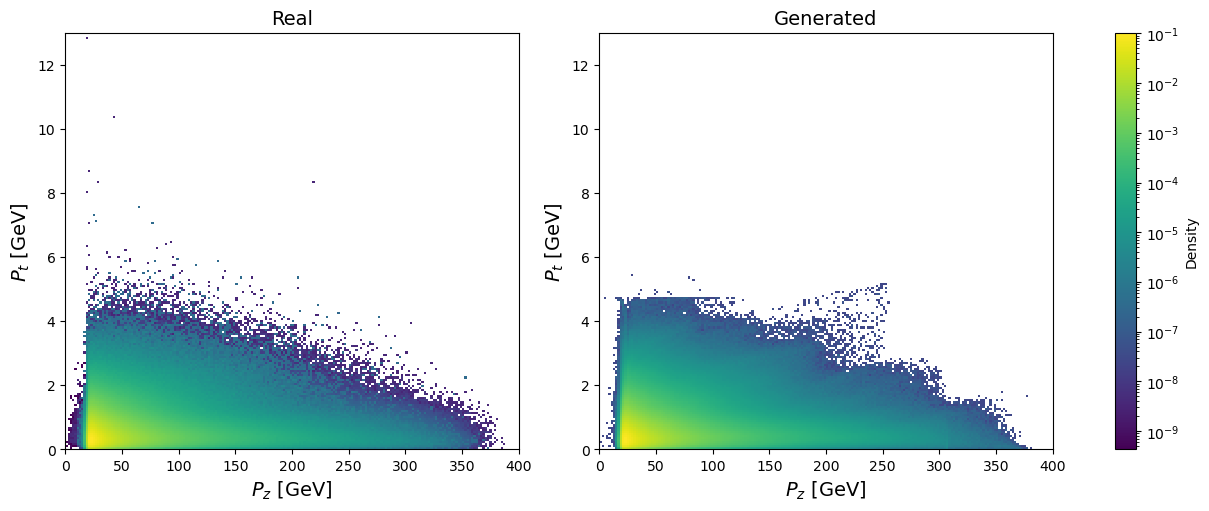

In [9]:
compare_2d_histograms(pz_real, pt_real, gen_pz, gen_pt, real_w=weights)

Weight: 0.09369999915361404, mean Z Position: -1.95 cm, std Z Position: 0.17 cm
Weight: 1.0, mean Z Position: -1.96 cm, std Z Position: 0.17 cm
Weight: 3.2616000175476074, mean Z Position: -1.98 cm, std Z Position: 0.17 cm
Weight: 7.6875, mean Z Position: -1.92 cm, std Z Position: 0.20 cm
Weight: 9.369999885559082, mean Z Position: -1.97 cm, std Z Position: 0.16 cm
Weight: 326.1600036621094, mean Z Position: -1.99 cm, std Z Position: 0.16 cm
Weight: 768.75, mean Z Position: -1.74 cm, std Z Position: 0.24 cm


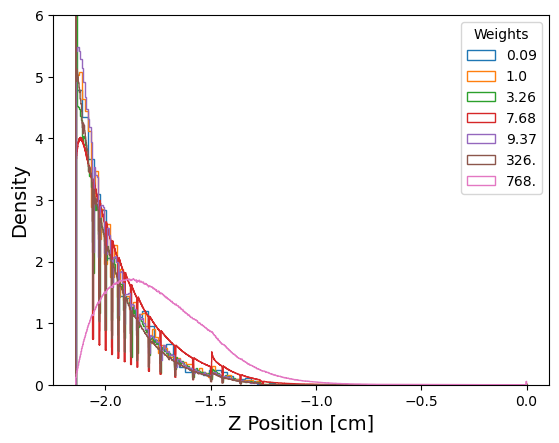

In [10]:
for w in data.keys():
    plt.hist(data[w][:,5], bins='auto', density=True, histtype='step',  label = str(w)[:4])
    print(f"Weight: {w}, mean Z Position: {np.mean(data[w][:,5]):.2f} cm, std Z Position: {np.std(data[w][:,5]):.2f} cm")
    plt.ylim(0, 6)
plt.legend(title='Weights', fontsize=10)
plt.xlabel('Z Position [cm]', fontsize=14)
plt.ylabel('Density', fontsize=14)
plt.show()

# Weight 0.09

In [11]:
i = 0
w = list(data.keys())[i]
model = models[w]
w

np.float32(0.0937)

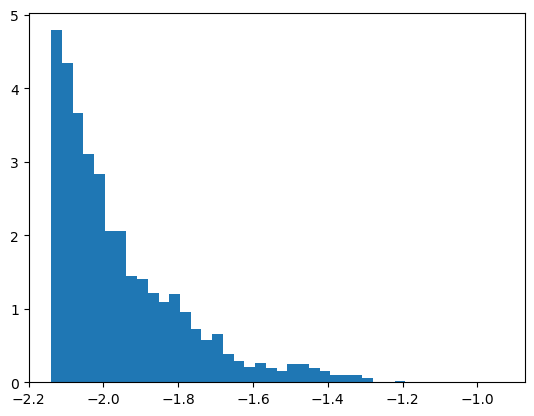

In [12]:
plt.hist(data[w][:,5], bins='auto', density=True, label='Real')
plt.show()

In [13]:
n_samples = 50e6
flow = model['flow'].to(device)
mean,std = model['mean'], model['std']
sample = batch_sample(flow, n_samples)
sample = sample * std + mean
gen_pz = sample[:, 0]
gen_pt = sample[:, 1]

In [14]:
pz_real = np.concatenate([data[w][:, 2]])
pt_real = np.sqrt(np.concatenate([data[w][:, 0]**2 + data[w][:, 1]**2]))

Number of real samples: 3311, Number of generated samples: 50000000


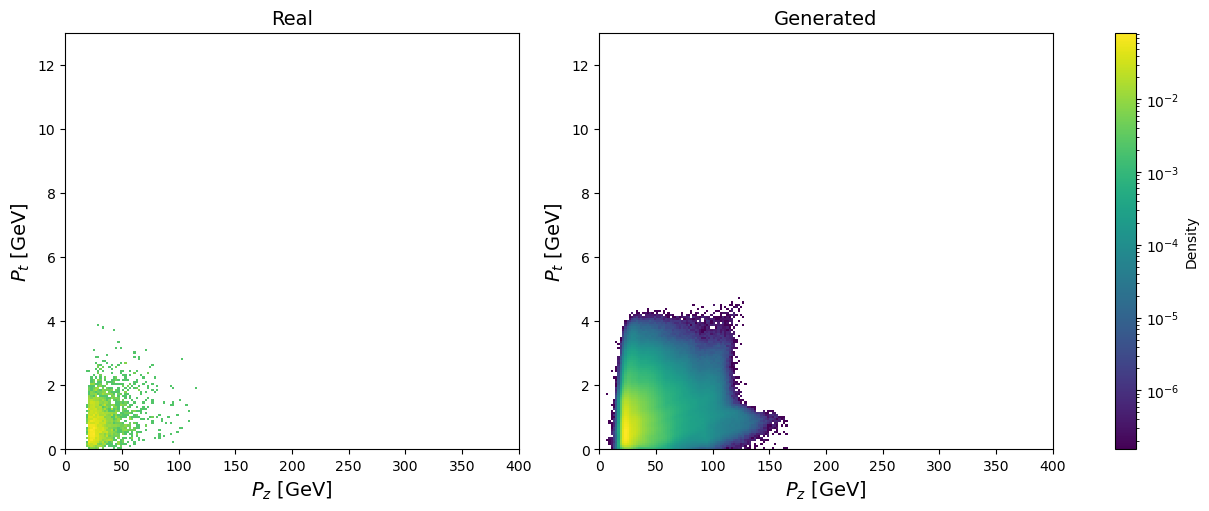

In [15]:
compare_2d_histograms(pz_real, pt_real, gen_pz, gen_pt)
print(f"Number of real samples: {pz_real.shape[0]}, Number of generated samples: {gen_pz.shape[0]}")

# Weight 1.0

In [16]:
i = 1
w = list(data.keys())[i]
model = models[w]
w

np.float32(1.0)

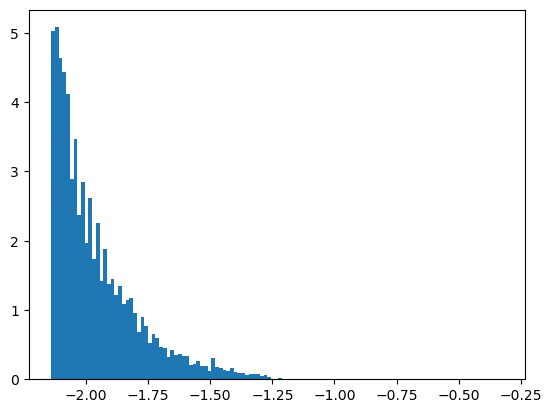

In [17]:
plt.hist(data[w][:,5], bins='auto', density=True, label='Real')
plt.show()

In [18]:
n_samples = 50e6
flow = model['flow'].to(device)
mean,std = model['mean'], model['std']
sample = batch_sample(flow, n_samples)
sample = sample * std + mean
gen_pz = sample[:, 0]
gen_pt = sample[:, 1]

In [19]:
pz_real = np.concatenate([data[w][:, 2]])
pt_real = np.sqrt(np.concatenate([data[w][:, 0]**2 + data[w][:, 1]**2]))

Number of real samples: 20993, Number of generated samples: 50000000


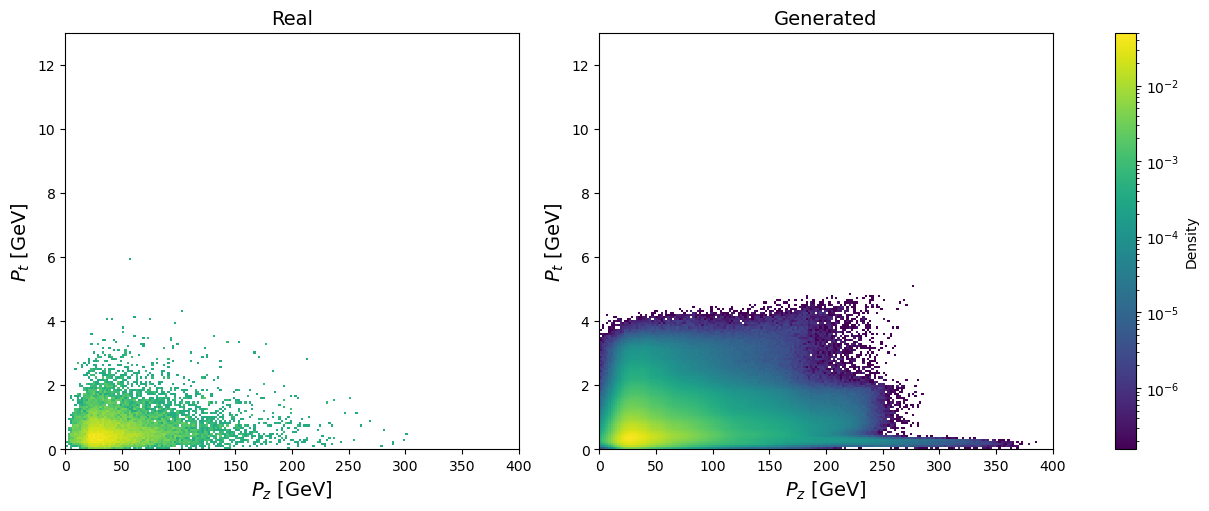

In [20]:
compare_2d_histograms(pz_real, pt_real, gen_pz, gen_pt)
print(f"Number of real samples: {pz_real.shape[0]}, Number of generated samples: {gen_pz.shape[0]}")

# Weight 3.26

In [21]:
i = 2
w = list(data.keys())[i]
model = models[w]
w

np.float32(3.2616)

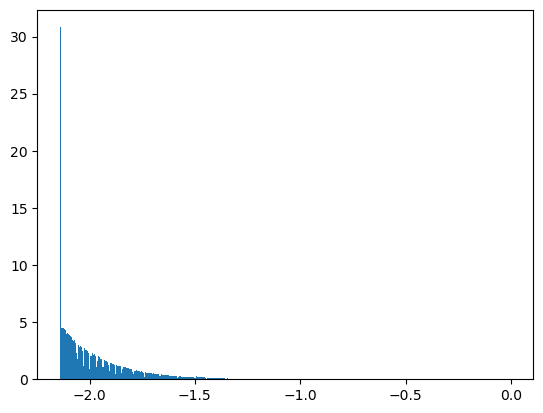

In [22]:
plt.hist(data[w][:,5], bins='auto', density=True, label='Real')
plt.show()

In [23]:
n_samples = 7e5
flow = model['flow'].to(device)
mean,std = model['mean'], model['std']
sample = batch_sample(flow, n_samples)
sample = sample * std + mean
gen_pz = sample[:, 0]
gen_pt = sample[:, 1]

In [24]:
pz_real = np.concatenate([data[w][:, 2]])
pt_real = np.sqrt(np.concatenate([data[w][:, 0]**2 + data[w][:, 1]**2]))

Number of real samples: 691113, Number of generated samples: 700000


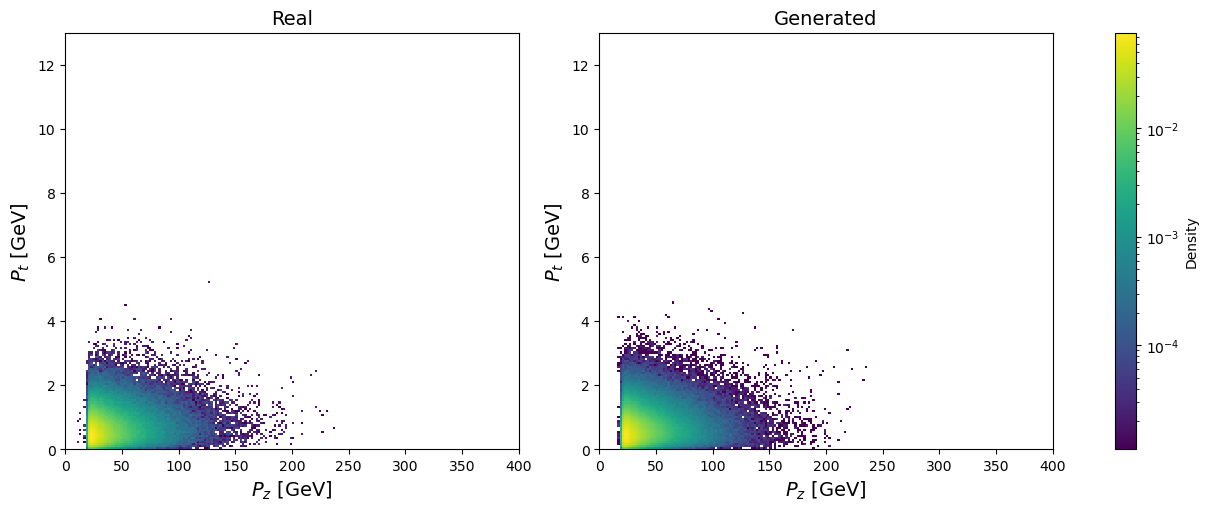

In [25]:
compare_2d_histograms(pz_real, pt_real, gen_pz, gen_pt)
print(f"Number of real samples: {pz_real.shape[0]}, Number of generated samples: {gen_pz.shape[0]}")

# Weight 7.69

In [46]:
i = 3
w = list(data.keys())[i]
model = models[w]
w

np.float32(7.6875)

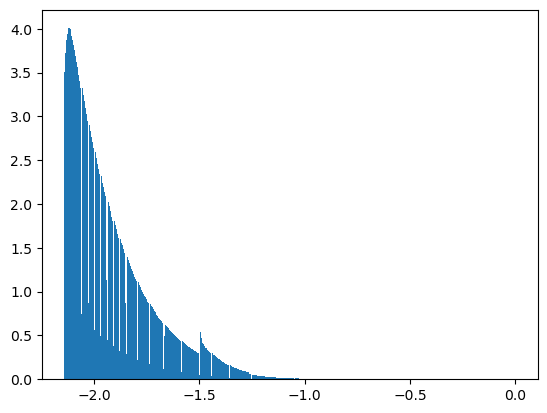

In [47]:
plt.hist(data[w][:,5], bins='auto', density=True, label='Real')
plt.show()

In [48]:
n_samples = 500e6
flow = model['flow'].to(device)
mean,std = model['mean'], model['std']
sample = batch_sample(flow, n_samples)
sample = sample * std + mean
gen_pz = sample[:, 0]
gen_pt = sample[:, 1]

In [49]:
pz_real = np.concatenate([data[w][:, 2]])
pt_real = np.sqrt(np.concatenate([data[w][:, 0]**2 + data[w][:, 1]**2]))

In [53]:
gen_pz.max()

np.float64(416.85153684883943)

(<Figure size 800x500 with 1 Axes>,
 <Axes: xlabel='$P_t$ [GeV]', ylabel='Density'>)

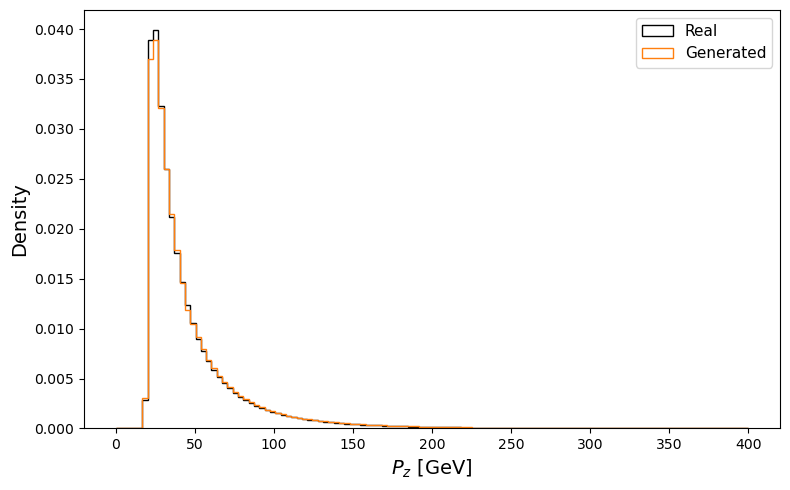

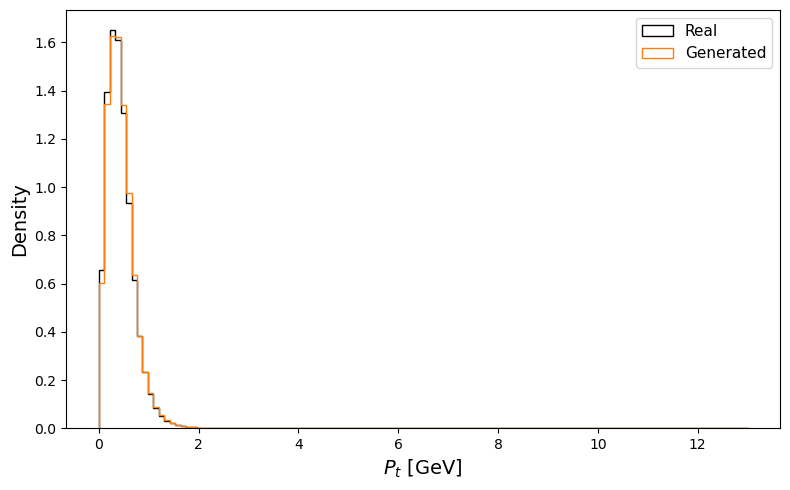

In [51]:
compare_1d_histograms(pz_real, gen_pz, bins=120, range_vals=(0, 400), xlabel='$P_z$ [GeV]', real_w=None)
compare_1d_histograms(pt_real, gen_pt, bins=120, range_vals=(0, 13), xlabel='$P_t$ [GeV]', real_w=None)

Number of real samples: 480474935, Number of generated samples: 500000000


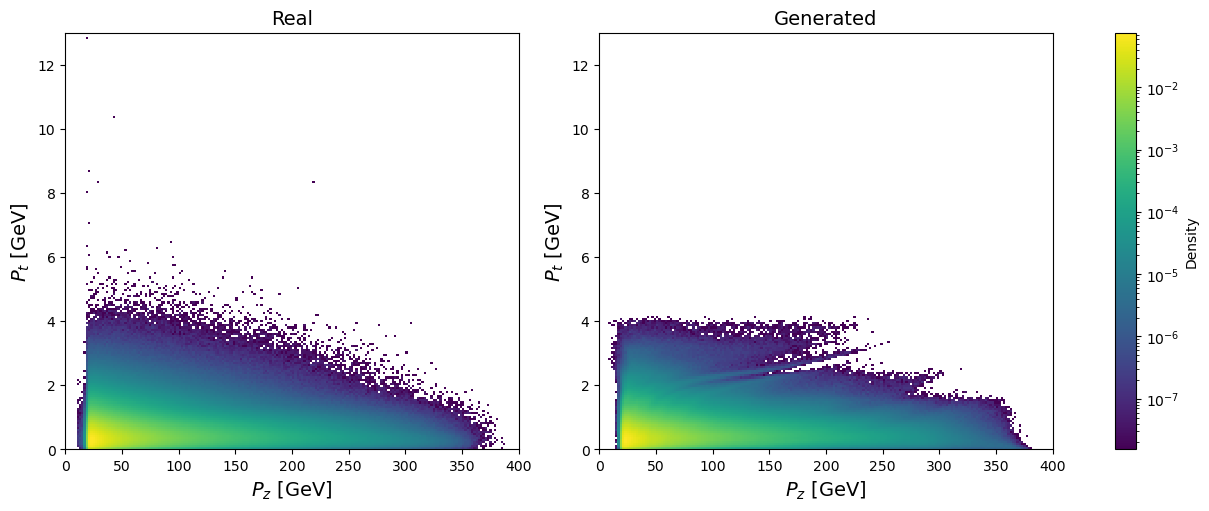

In [50]:
compare_2d_histograms(pz_real, pt_real, gen_pz, gen_pt)
print(f"Number of real samples: {pz_real.shape[0]}, Number of generated samples: {gen_pz.shape[0]}")

# Weight 9.37

In [31]:
i = 4
w = list(data.keys())[i]
model = models[w]
w

np.float32(9.37)

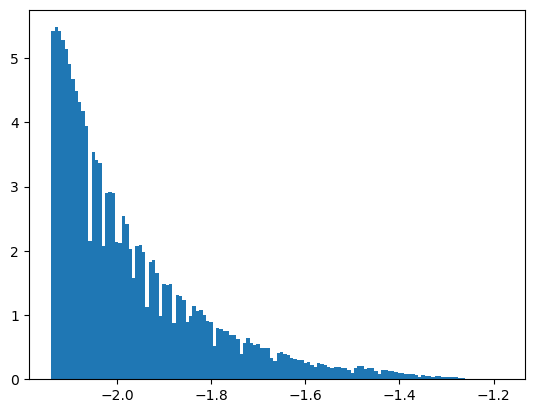

In [32]:
plt.hist(data[w][:,5], bins='auto', density=True, label='Real')
plt.show()

In [33]:
n_samples = 50e6
flow = model['flow'].to(device)
mean,std = model['mean'], model['std']
sample = batch_sample(flow, n_samples)
sample = sample * std + mean
gen_pz = sample[:, 0]
gen_pt = sample[:, 1]

In [34]:
pz_real = np.concatenate([data[w][:, 2]])
pt_real = np.sqrt(np.concatenate([data[w][:, 0]**2 + data[w][:, 1]**2]))

Number of real samples: 168445, Number of generated samples: 50000000


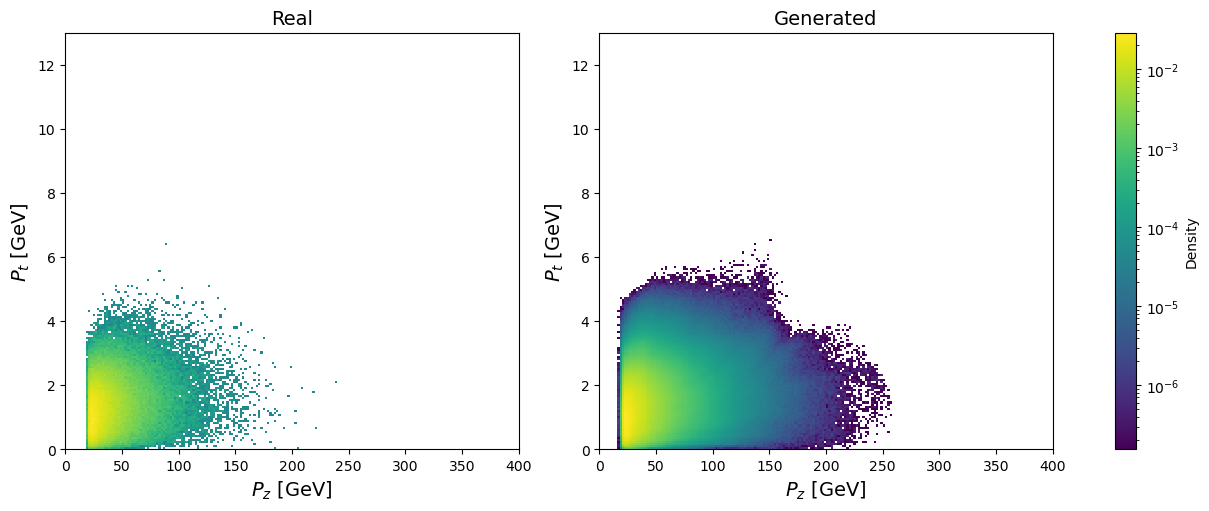

In [35]:
compare_2d_histograms(pz_real, pt_real, gen_pz, gen_pt)
print(f"Number of real samples: {pz_real.shape[0]}, Number of generated samples: {gen_pz.shape[0]}")

# Weight 326.16

In [36]:
i = 5
w = list(data.keys())[i]
model = models[w]
w

np.float32(326.16)

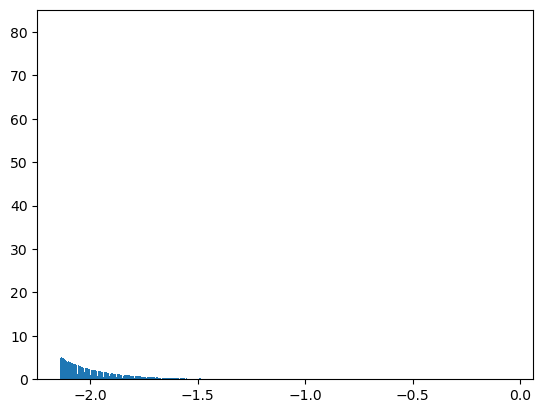

In [37]:
plt.hist(data[w][:,5], bins='auto', density=True, label='Real')
plt.show()

In [38]:
n_samples = 12e6
flow = model['flow'].to(device)
mean,std = model['mean'], model['std']
sample = batch_sample(flow, n_samples)
sample = sample * std + mean
gen_pz = sample[:, 0]
gen_pt = sample[:, 1]

In [39]:
pz_real = np.concatenate([data[w][:, 2]])
pt_real = np.sqrt(np.concatenate([data[w][:, 0]**2 + data[w][:, 1]**2]))

Number of real samples: 11094133, Number of generated samples: 12000000


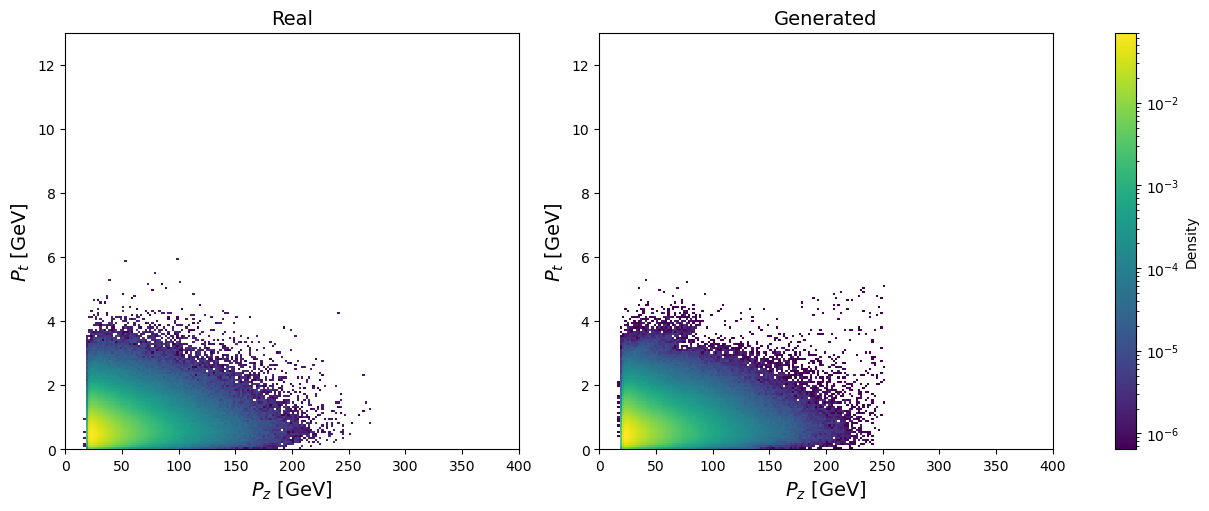

In [40]:
compare_2d_histograms(pz_real, pt_real, gen_pz, gen_pt)
print(f"Number of real samples: {pz_real.shape[0]}, Number of generated samples: {gen_pz.shape[0]}")

# Weight 768.75

In [41]:
i = 6
w = list(data.keys())[i]
model = models[w]
w

np.float32(768.75)

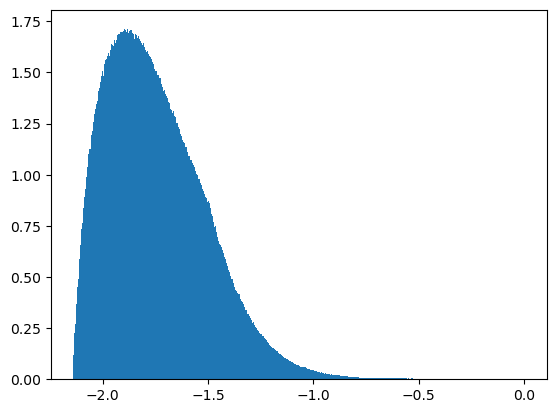

In [42]:
plt.hist(data[w][:,5], bins='auto', density=True, label='Real')
plt.show()

In [43]:
n_samples = 15e6
flow = model['flow'].to(device)
mean,std = model['mean'], model['std']
sample = batch_sample(flow, n_samples)
sample = sample * std + mean
gen_pz = sample[:, 0]
gen_pt = sample[:, 1]

In [44]:
pz_real = np.concatenate([data[w][:, 2]])
pt_real = np.sqrt(np.concatenate([data[w][:, 0]**2 + data[w][:, 1]**2]))

Number of real samples: 13921031, Number of generated samples: 15000000


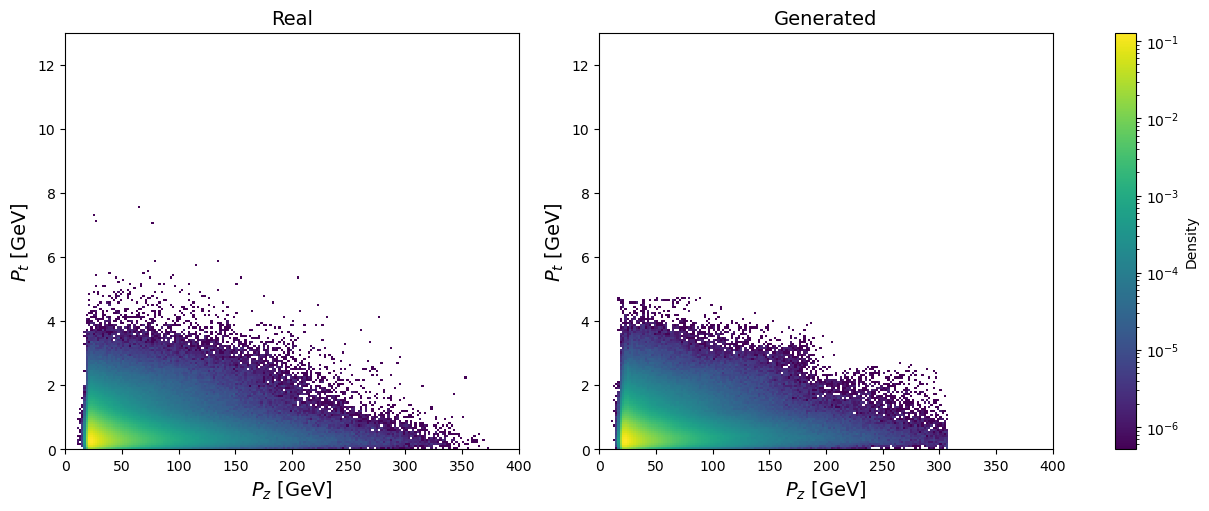

In [45]:
compare_2d_histograms(pz_real, pt_real, gen_pz, gen_pt)
print(f"Number of real samples: {pz_real.shape[0]}, Number of generated samples: {gen_pz.shape[0]}")